In [4]:
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.width", 200)

_here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [_here, *_here.parents]
                     if (p/"data"/"processed"/"era5_algeria_masked_2x2_v2.nc").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("era5_algeria_masked_2x2_v2.nc introuvable : exécutez d'abord le notebook 01.")
ds = xr.open_dataset(PROJECT_ROOT/"data"/"processed"/"era5_algeria_masked_2x2_v2.nc")

step = float(abs(ds.latitude.diff("latitude")).mean())
print("Dimensions :", dict(ds.sizes), "| pas de grille ≈", round(step, 3), "°")
print("=> données 2x2 confirmées" if abs(step-0.2) < 0.02 else "!! ATTENTION : ce n'est pas la grille 2x2 (pas attendu 0.2°)")

Dimensions : {'valid_time': 141, 'latitude': 95, 'longitude': 105} | pas de grille ≈ 0.2 °
=> données 2x2 confirmées


## 0. Conversion des unités (sur la grille, cellule par cellule)

In [5]:
BASE = ["d2m","t2m","slhf","ssr","str","sshf","ro","e","u10","v10","sp","tp"]
LABELS = {"d2m":"Point de rosée 2 m (°C)","t2m":"Température 2 m (°C)","slhf":"Flux chaleur latente (W/m²)",
          "ssr":"Rayonnement solaire net (W/m²)","str":"Rayonnement thermique net (W/m²)","sshf":"Flux chaleur sensible (W/m²)",
          "ro":"Ruissellement (mm/j)","e":"Évaporation (mm/j)","u10":"Vent u10 (m/s)","v10":"Vent v10 (m/s)",
          "sp":"Pression surface (hPa)","tp":"Précipitation (mm/j)","wind10_speed":"Vitesse du vent 10 m (m/s)"}
conv = xr.Dataset(coords=ds.coords)
for v in ["d2m","t2m"]:               conv[v] = ds[v] - 273.15
for v in ["slhf","ssr","str","sshf"]: conv[v] = ds[v] / 86400.0
for v in ["ro","e","tp"]:             conv[v] = ds[v] * 1000.0
conv["sp"]  = ds["sp"] / 100.0
conv["u10"], conv["v10"] = ds["u10"], ds["v10"]
conv["wind10_speed"] = np.hypot(ds["u10"], ds["v10"])
ALL = BASE + ["wind10_speed"]

# moyenne régionale pondérée par cos(latitude) ; les cellules NaN (hors Algérie) sont ignorées
w = np.cos(np.deg2rad(conv.latitude))
regional = pd.DataFrame({v: conv[v].weighted(w).mean(("latitude","longitude")).to_series() for v in ALL})
regional.index = pd.to_datetime(regional.index)
print(regional.shape, "|", regional.index.min().date(), "→", regional.index.max().date())
display(regional.head(3).round(3))

(141, 13) | 2015-01-01 → 2026-09-01


,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp,wind10_speed
valid_time,,,,,,,,,,,,,
2015-01-01,-4.328,10.711,-4.800,113.683,-95.358,-15.894,0.007,-0.166,-0.711,-0.990,957.947,0.223,2.074
2015-02-01,-2.711,13.697,-9.510,134.561,-99.493,-26.835,0.017,-0.328,0.451,-0.945,951.289,0.540,1.518
2015-03-01,-2.312,16.781,-12.023,168.035,-113.094,-41.513,0.017,-0.415,-0.569,-0.784,952.576,0.368,1.345


## 1. Qualité des données (sur la grille 2×2)

In [6]:
valid_cells = conv["t2m"].notnull().any("valid_time")
partial = conv["t2m"].isnull().any("valid_time") & valid_cells
print("Cellules 2x2 contenant au moins une valeur :", int(valid_cells.sum()))
print("Cellules partiellement manquantes (certains mois seulement) :", int(partial.sum()))
nan_by_var = pd.Series({v: int(conv[v].where(valid_cells).isnull().sum()) for v in ALL}, name="NaN dans le domaine")
display(nan_by_var.to_frame())
print("NaN dans les séries régionales :", int(regional.isna().sum().sum()))

Cellules 2x2 contenant au moins une valeur : 5424
Cellules partiellement manquantes (certains mois seulement) : 0


,NaN dans le domaine
d2m,641691
t2m,641691
slhf,641691
ssr,641691
str,641691
sshf,641691
ro,641691
e,641691
u10,641691
v10,641691


NaN dans les séries régionales : 0


## 2. Analyse **univariée** — toutes les variables

In [7]:
UNITS = {
    "d2m": "°C", "t2m": "°C",
    "slhf": "W/m²", "ssr": "W/m²", "str": "W/m²", "sshf": "W/m²",
    "ro": "mm/jour", "e": "mm/jour", "tp": "mm/jour",
    "u10": "m/s", "v10": "m/s", "wind10_speed": "m/s",
    "sp": "hPa",
}

def describe(df):
    s = pd.DataFrame({"moyenne": df.mean(), "médiane": df.median(), "écart-type": df.std(ddof=1),
                      "min": df.min(), "Q1": df.quantile(.25), "Q3": df.quantile(.75), "max": df.max()})
    s["IQR"] = s["Q3"] - s["Q1"]
    s.insert(0, "unité", [UNITS.get(v, "?") for v in s.index]) 
    s.index.name = "variable"
    return s

summary = describe(regional)
display(summary.round(3))

,unité,moyenne,médiane,écart-type,min,Q1,Q3,max,IQR
variable,,,,,,,,,
d2m,°C,1.449,1.486,3.679,-5.448,-1.717,4.016,12.258,5.732
t2m,°C,24.005,24.592,7.965,9.632,16.802,31.631,35.654,14.829
slhf,W/m²,-5.550,-5.149,2.691,-14.246,-7.269,-3.808,-1.199,3.462
ssr,W/m²,156.599,165.698,45.344,56.930,116.639,197.636,216.651,80.997
str,W/m²,-110.535,-114.786,26.485,-144.423,-131.045,-97.017,-45.569,34.028
sshf,W/m²,-39.291,-42.310,18.392,-63.599,-57.285,-20.565,-5.737,36.720
ro,mm/jour,0.003,0.002,0.003,0.000,0.001,0.004,0.017,0.003
e,mm/jour,-0.192,-0.178,0.093,-0.492,-0.251,-0.132,-0.041,0.120
u10,m/s,-1.048,-1.123,0.830,-2.786,-1.629,-0.507,1.429,1.121


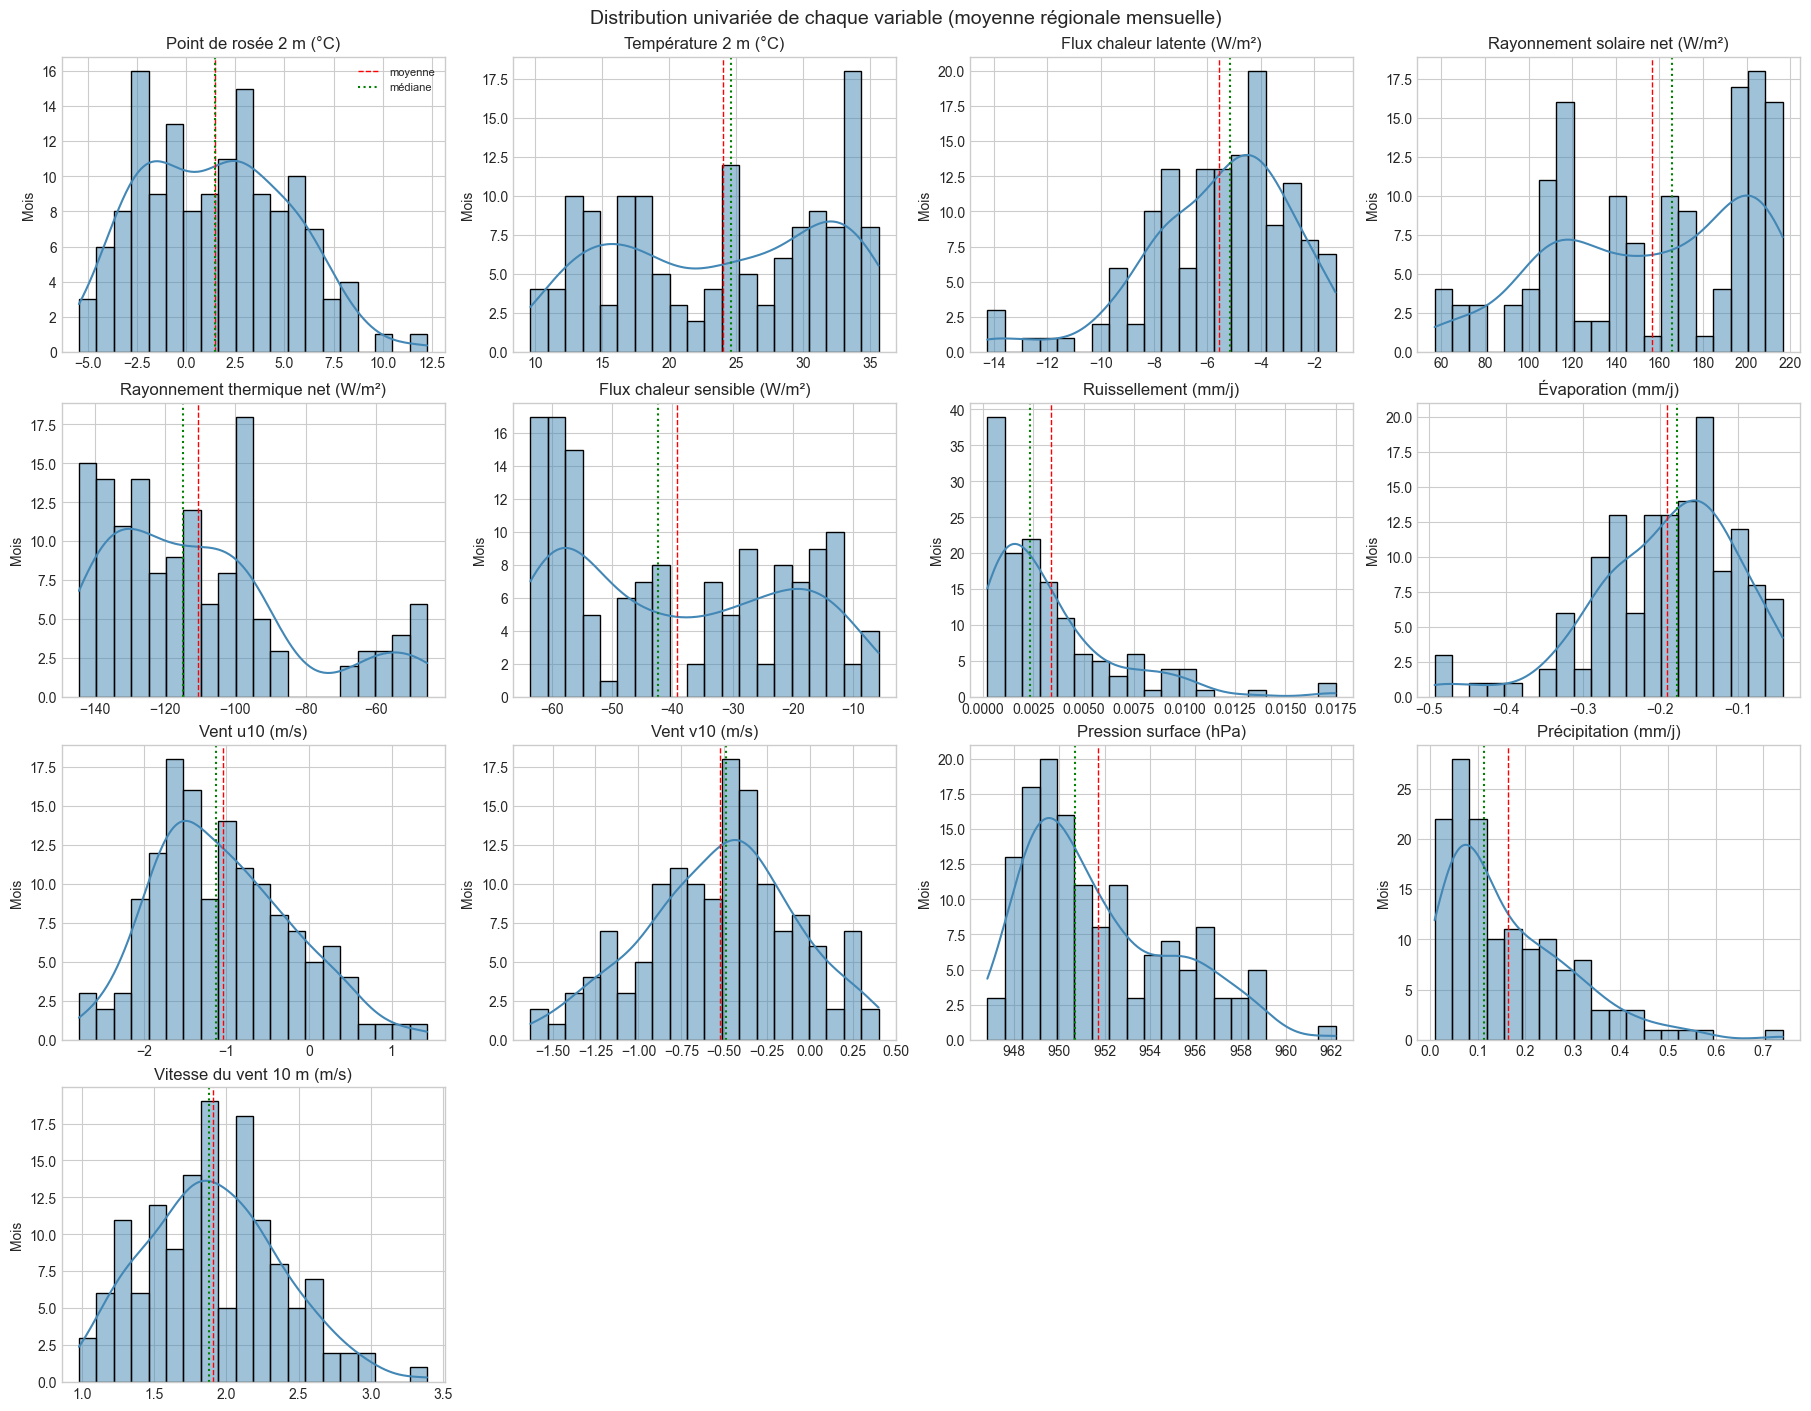

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14), constrained_layout=True)
for ax, v in zip(axes.flat, ALL):
    sns.histplot(regional[v], kde=True, bins=20, ax=ax, color="#4287b5")
    ax.axvline(regional[v].mean(), color="red", ls="--", lw=1, label="moyenne")
    ax.axvline(regional[v].median(), color="green", ls=":", lw=1.5, label="médiane")
    ax.set(title=LABELS[v], xlabel="", ylabel="Mois")
axes.flat[0].legend(fontsize=8)
for ax in axes.flat[len(ALL):]: ax.set_visible(False)
fig.suptitle("Distribution univariée de chaque variable (moyenne régionale mensuelle)", fontsize=14)
plt.show()

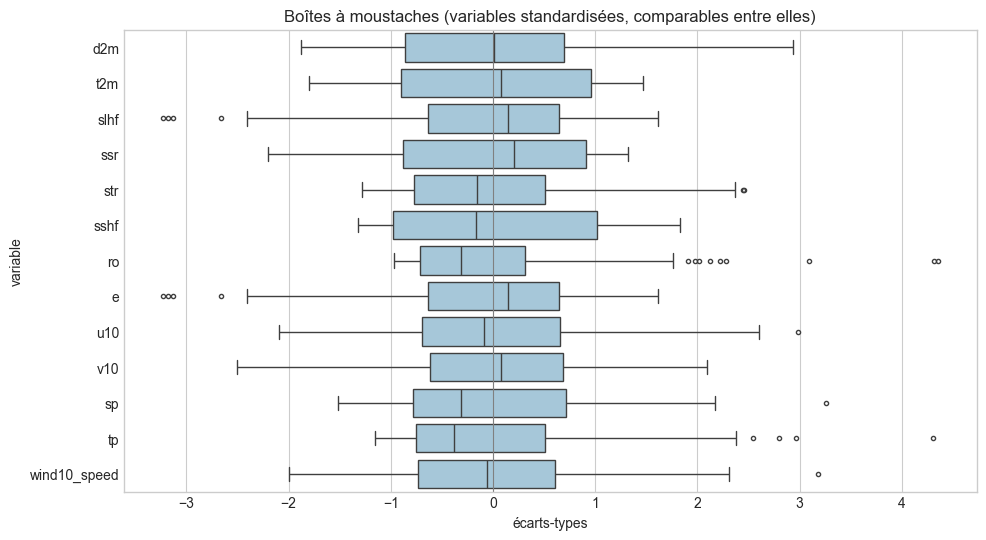

variable,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp,wind10_speed
outliers (1.5×IQR),0,0,4,0,2,0,9,4,1,0,1,4,1


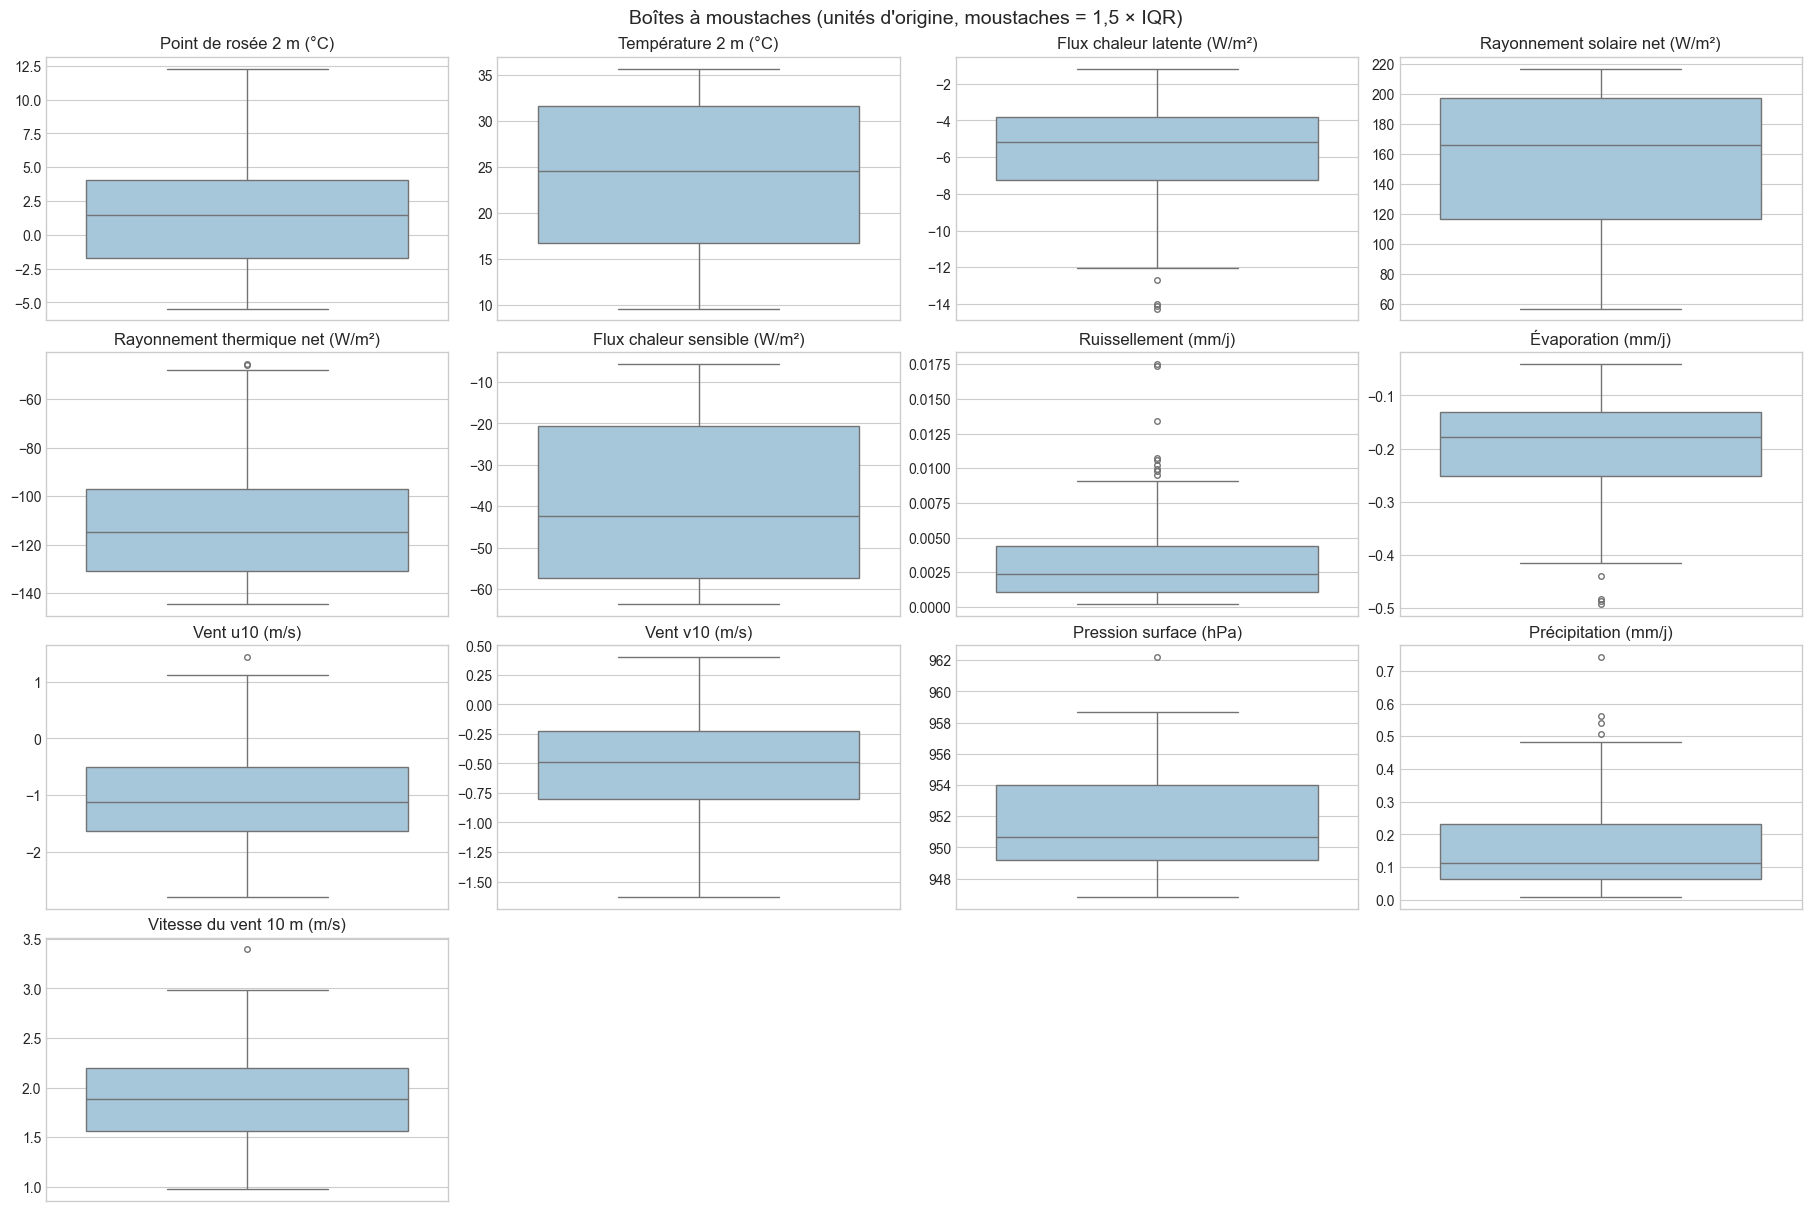

In [18]:
z = (regional - regional.mean()) / regional.std()
plt.figure(figsize=(11, 6))
sns.boxplot(data=z, orient="h", color="#9ecae1", fliersize=3)
plt.axvline(0, color="grey", lw=.8)
plt.title("Boîtes à moustaches (variables standardisées, comparables entre elles)")
plt.xlabel("écarts-types"); plt.yticks(range(len(ALL)), ALL); plt.show()

rows = []
for v in ALL:
    q1, q3 = regional[v].quantile([.25, .75]); i = q3 - q1
    n = int(((regional[v] < q1 - 1.5*i) | (regional[v] > q3 + 1.5*i)).sum())
    rows.append({"variable": v, "outliers (1.5×IQR)": n})
display(pd.DataFrame(rows).set_index("variable").T)


fig, axes = plt.subplots(4, 4, figsize=(18, 12), constrained_layout=True)
for ax, v in zip(axes.flat, ALL):
    sns.boxplot(y=regional[v], ax=ax, color="#9ecae1", whis=1.5, fliersize=4)
    ax.set(title=LABELS[v], ylabel="")
for ax in axes.flat[len(ALL):]: ax.set_visible(False)
fig.suptitle("Boîtes à moustaches (unités d'origine, moustaches = 1,5 × IQR)", fontsize=14)
plt.show()

## 3. Séries temporelles et saisonnalité (toutes les variables)

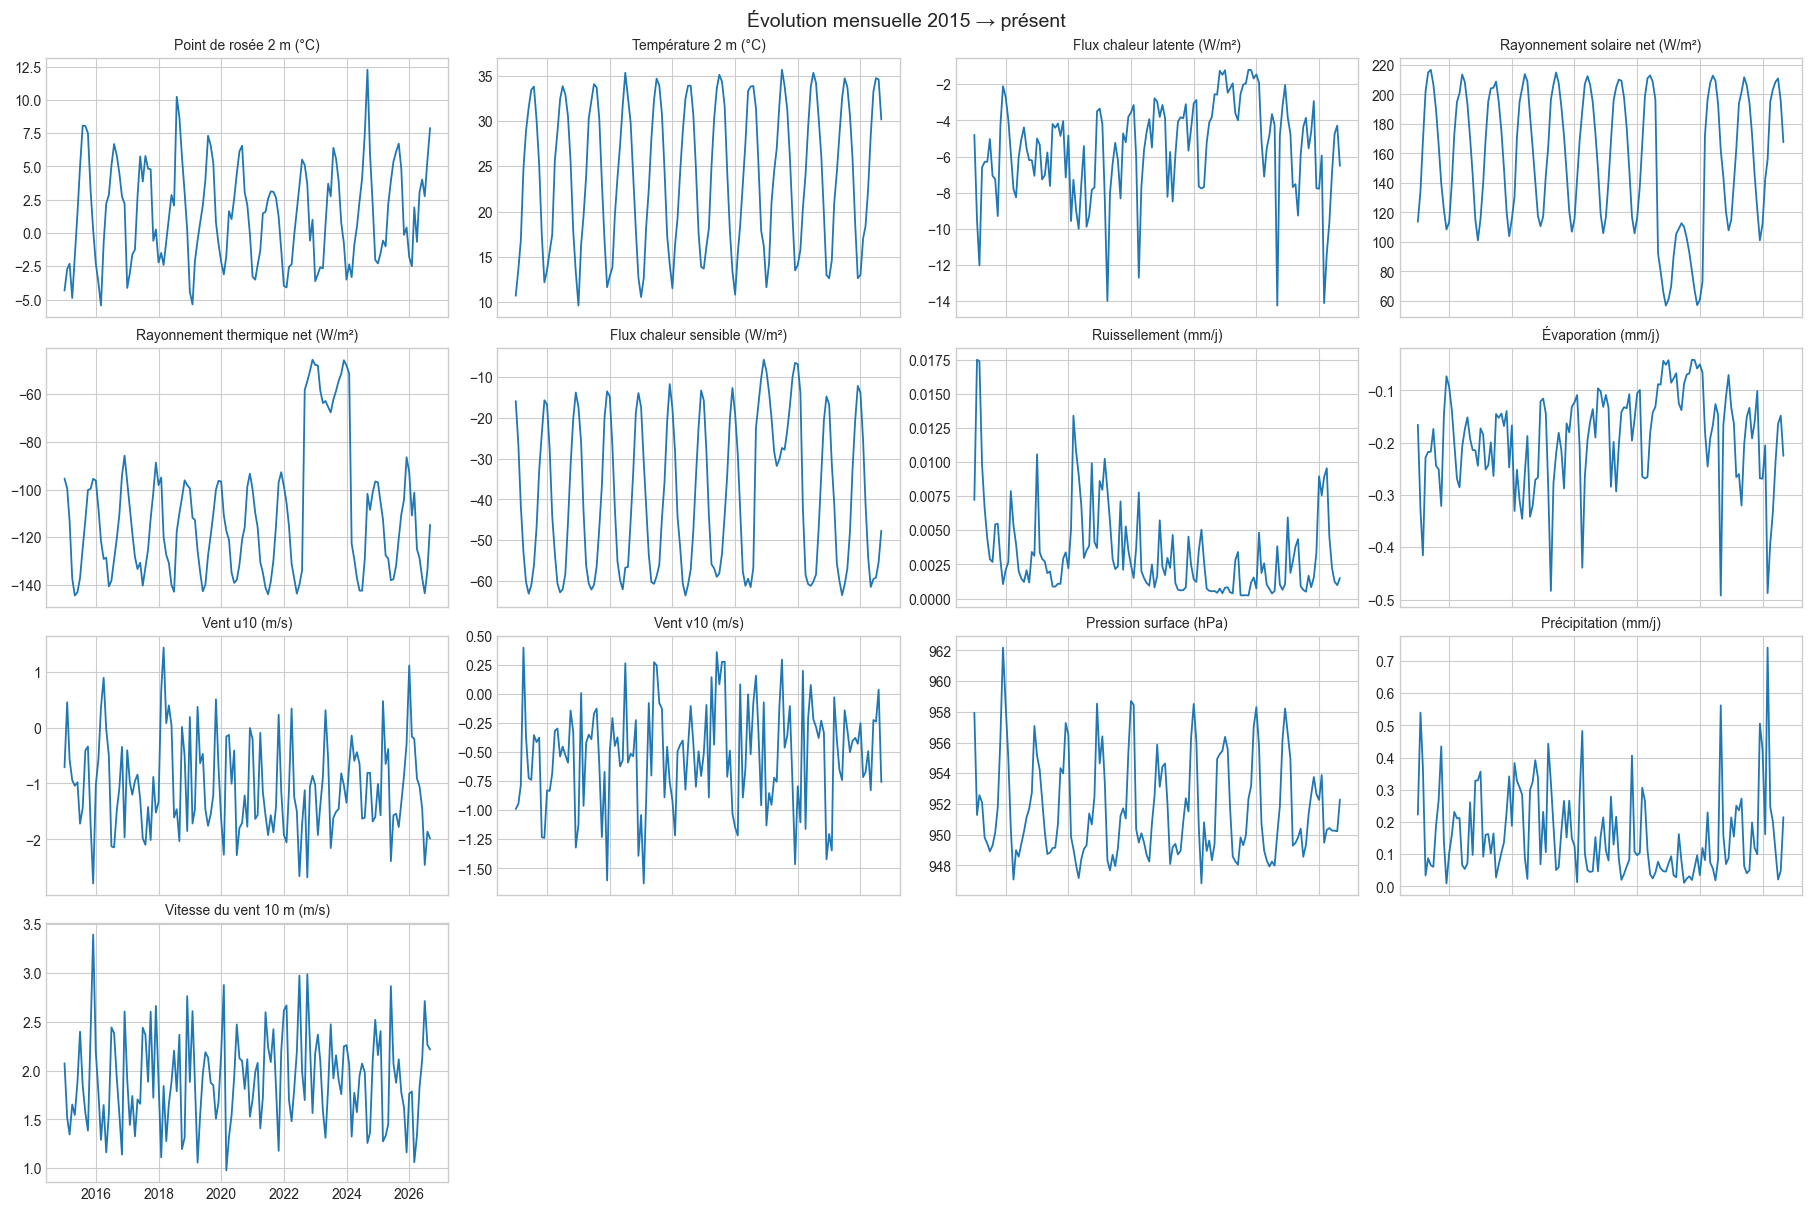

In [10]:
fig, axes = plt.subplots(4, 4, figsize=(18, 12), constrained_layout=True, sharex=True)
for ax, v in zip(axes.flat, ALL):
    ax.plot(regional.index, regional[v], lw=1.3)
    ax.set_title(LABELS[v], fontsize=10)
for ax in axes.flat[len(ALL):]: ax.set_visible(False)
fig.suptitle("Évolution mensuelle 2015 → présent", fontsize=14); plt.show()

## 4. Analyse **bivariée** — chaque variable vs `t2m`

In [12]:
anom = regional - regional.groupby(regional.index.month).transform("mean")
target_next = regional["t2m"].shift(-1)

def corr_table(X, y, name):
    d = pd.concat([X, y.rename("y")], axis=1).dropna()
    return pd.DataFrame({f"Pearson {name}": [stats.pearsonr(d[c], d["y"])[0] for c in X.columns],
                         f"Spearman {name}": [stats.spearmanr(d[c], d["y"])[0] for c in X.columns]}, index=X.columns)

others = [v for v in ALL if v != "t2m"]
biv = pd.concat([corr_table(regional[others], regional["t2m"], "t2m(t)"),
                 corr_table(regional[others], target_next, "t2m(t+1)"),
                 corr_table(anom[others], anom["t2m"], "anomalies")], axis=1)
display(biv.round(2))


'''
1. Pearson : corrélation linéaire
Pearson mesure à quel point les points suivent une ligne droite.
- Proche de +1 : quand X augmente, Y augmente.
- Proche de -1 : quand X augmente, Y diminue.
- Proche de 0 : pas de relation linéaire claire.

Spearman ne regarde pas directement les valeurs : il regarde plutôt leur classement (rang) : il détectera donc une forte corrélation positive.
'''

,Pearson t2m(t),Spearman t2m(t),Pearson t2m(t+1),Spearman t2m(t+1),Pearson anomalies,Spearman anomalies
variable,,,,,,
d2m,0.74,0.74,0.37,0.38,-0.01,-0.04
slhf,-0.12,-0.12,-0.28,-0.29,0.37,0.37
ssr,0.70,0.70,0.81,0.81,-0.15,-0.04
str,-0.55,-0.70,-0.63,-0.78,0.12,-0.09
sshf,-0.80,-0.78,-0.90,-0.89,0.20,0.38
ro,-0.32,-0.38,-0.10,-0.14,-0.45,-0.42
e,-0.12,-0.12,-0.28,-0.29,0.37,0.37
u10,-0.29,-0.32,-0.09,-0.12,-0.01,0.01
v10,0.60,0.60,0.50,0.46,0.52,0.53


'\n1. Pearson : corrélation linéaire\nPearson mesure à quel point les points suivent une ligne droite.\n- Proche de +1 : quand X augmente, Y augmente.\n- Proche de -1 : quand X augmente, Y diminue.\n- Proche de 0 : pas de relation linéaire claire.\n\nSpearman ne regarde pas directement les valeurs : il regarde plutôt leur classement (rang) : il détectera donc une forte corrélation positive.\n'

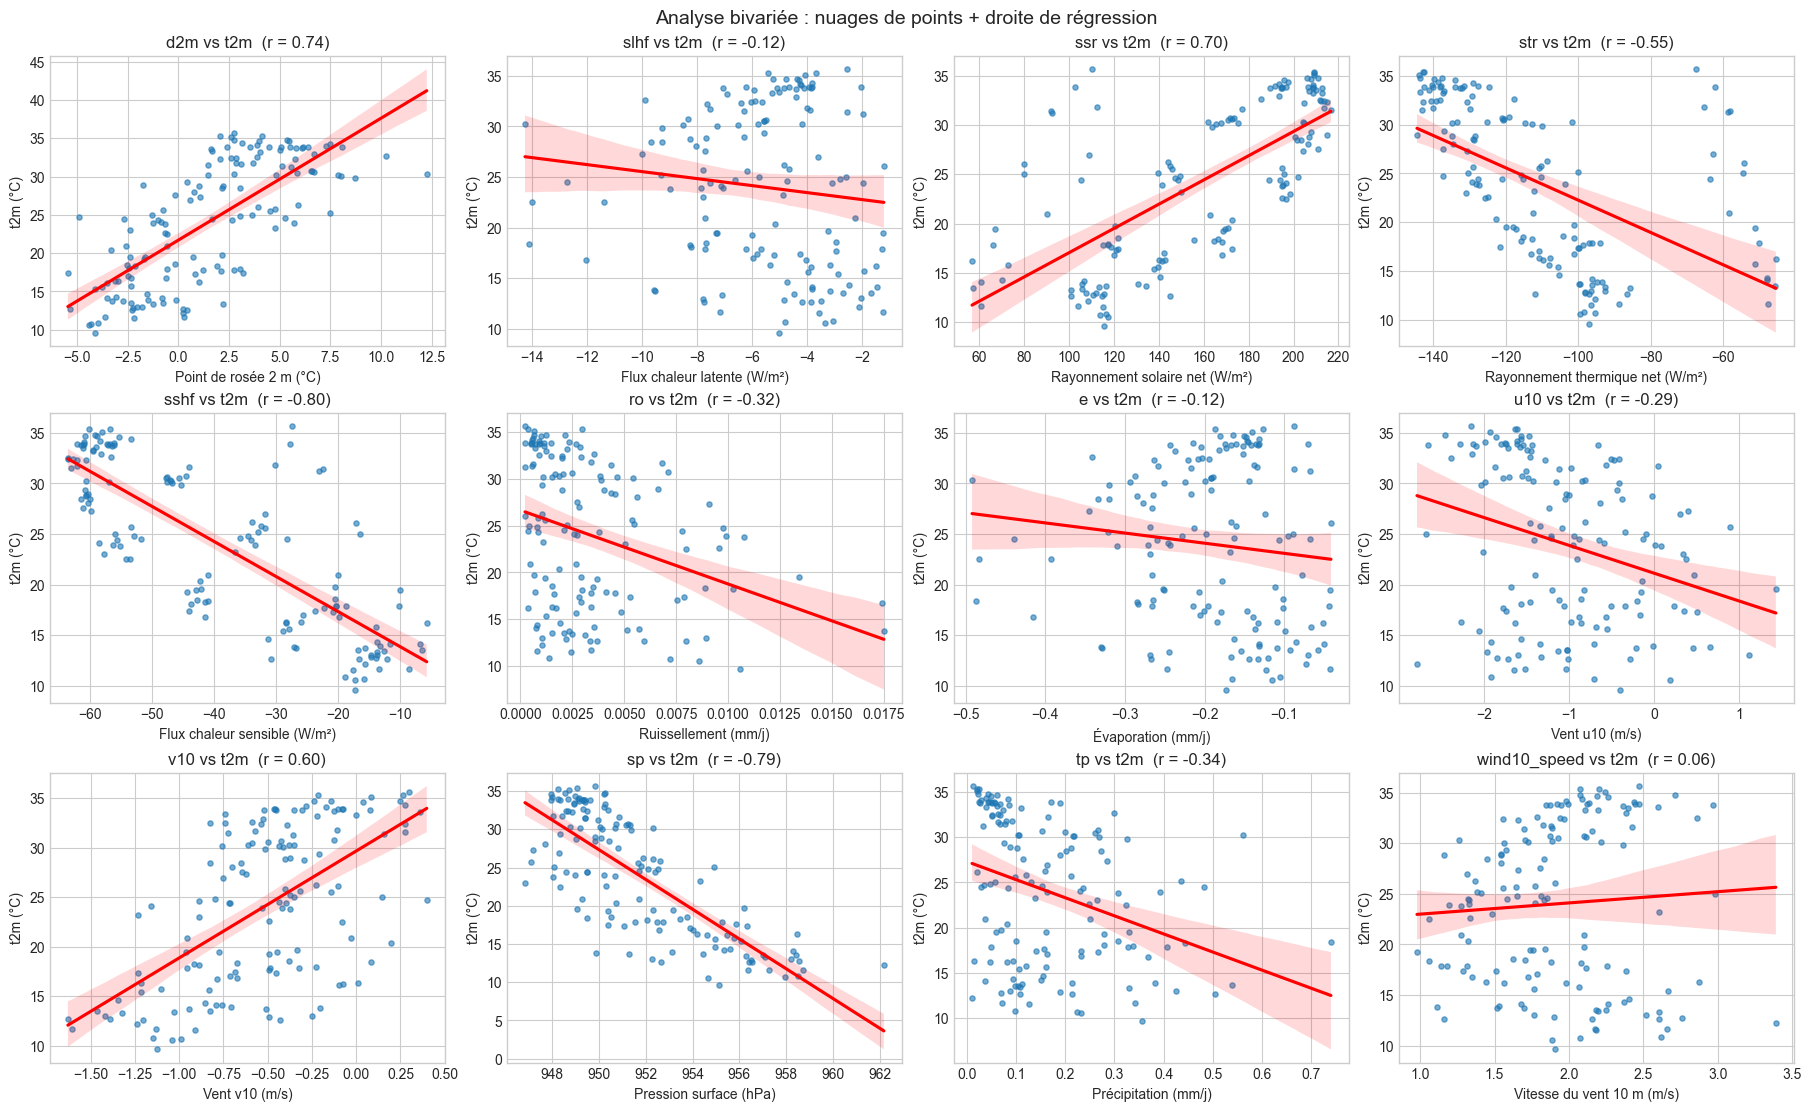

In [13]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11), constrained_layout=True)
for ax, v in zip(axes.flat, others):
    sns.regplot(x=regional[v], y=regional["t2m"], ax=ax, scatter_kws={"s": 14, "alpha": .6}, line_kws={"color": "red"})
    r = regional[[v, "t2m"]].corr().iloc[0, 1]
    ax.set(title=f"{v} vs t2m  (r = {r:.2f})", xlabel=LABELS[v], ylabel="t2m (°C)")
fig.suptitle("Analyse bivariée : nuages de points + droite de régression", fontsize=14); plt.show()

## 5. Analyse **multivariée**

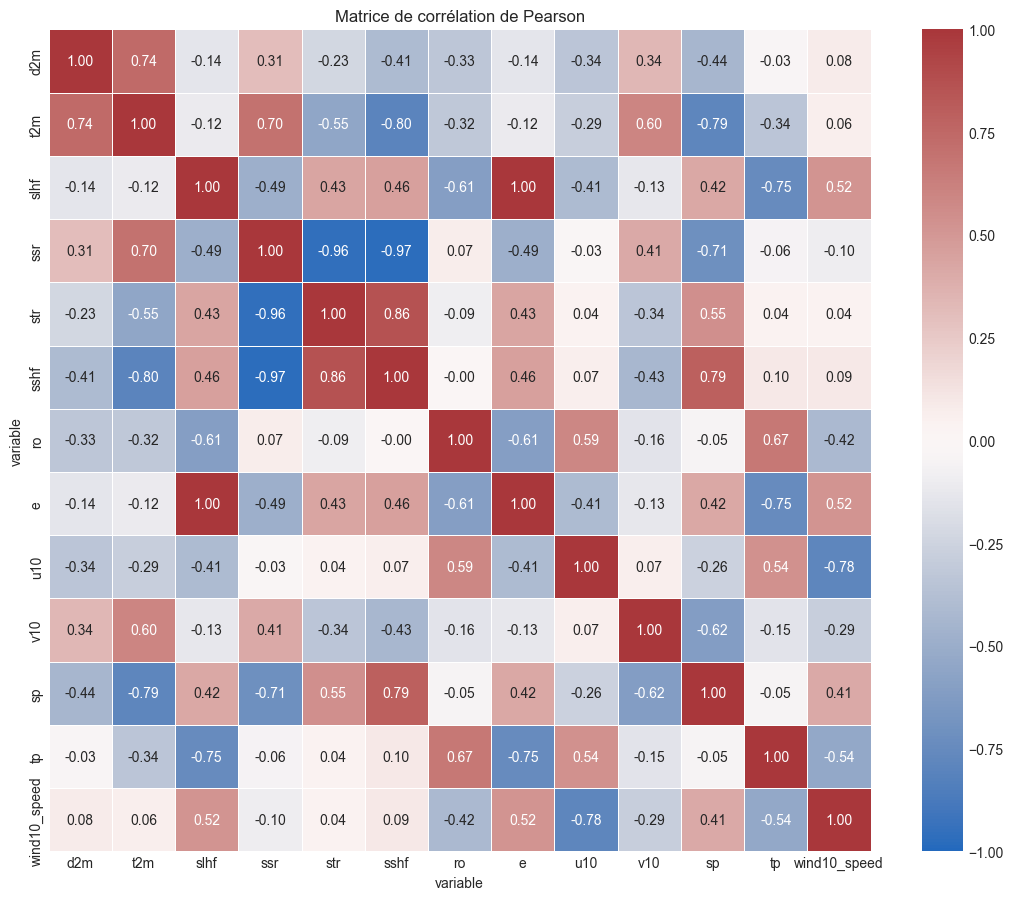

In [14]:
corr = regional[ALL].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Matrice de corrélation de Pearson")
plt.tight_layout()
plt.show()

## 6. Dimension spatiale (grille 2×2)

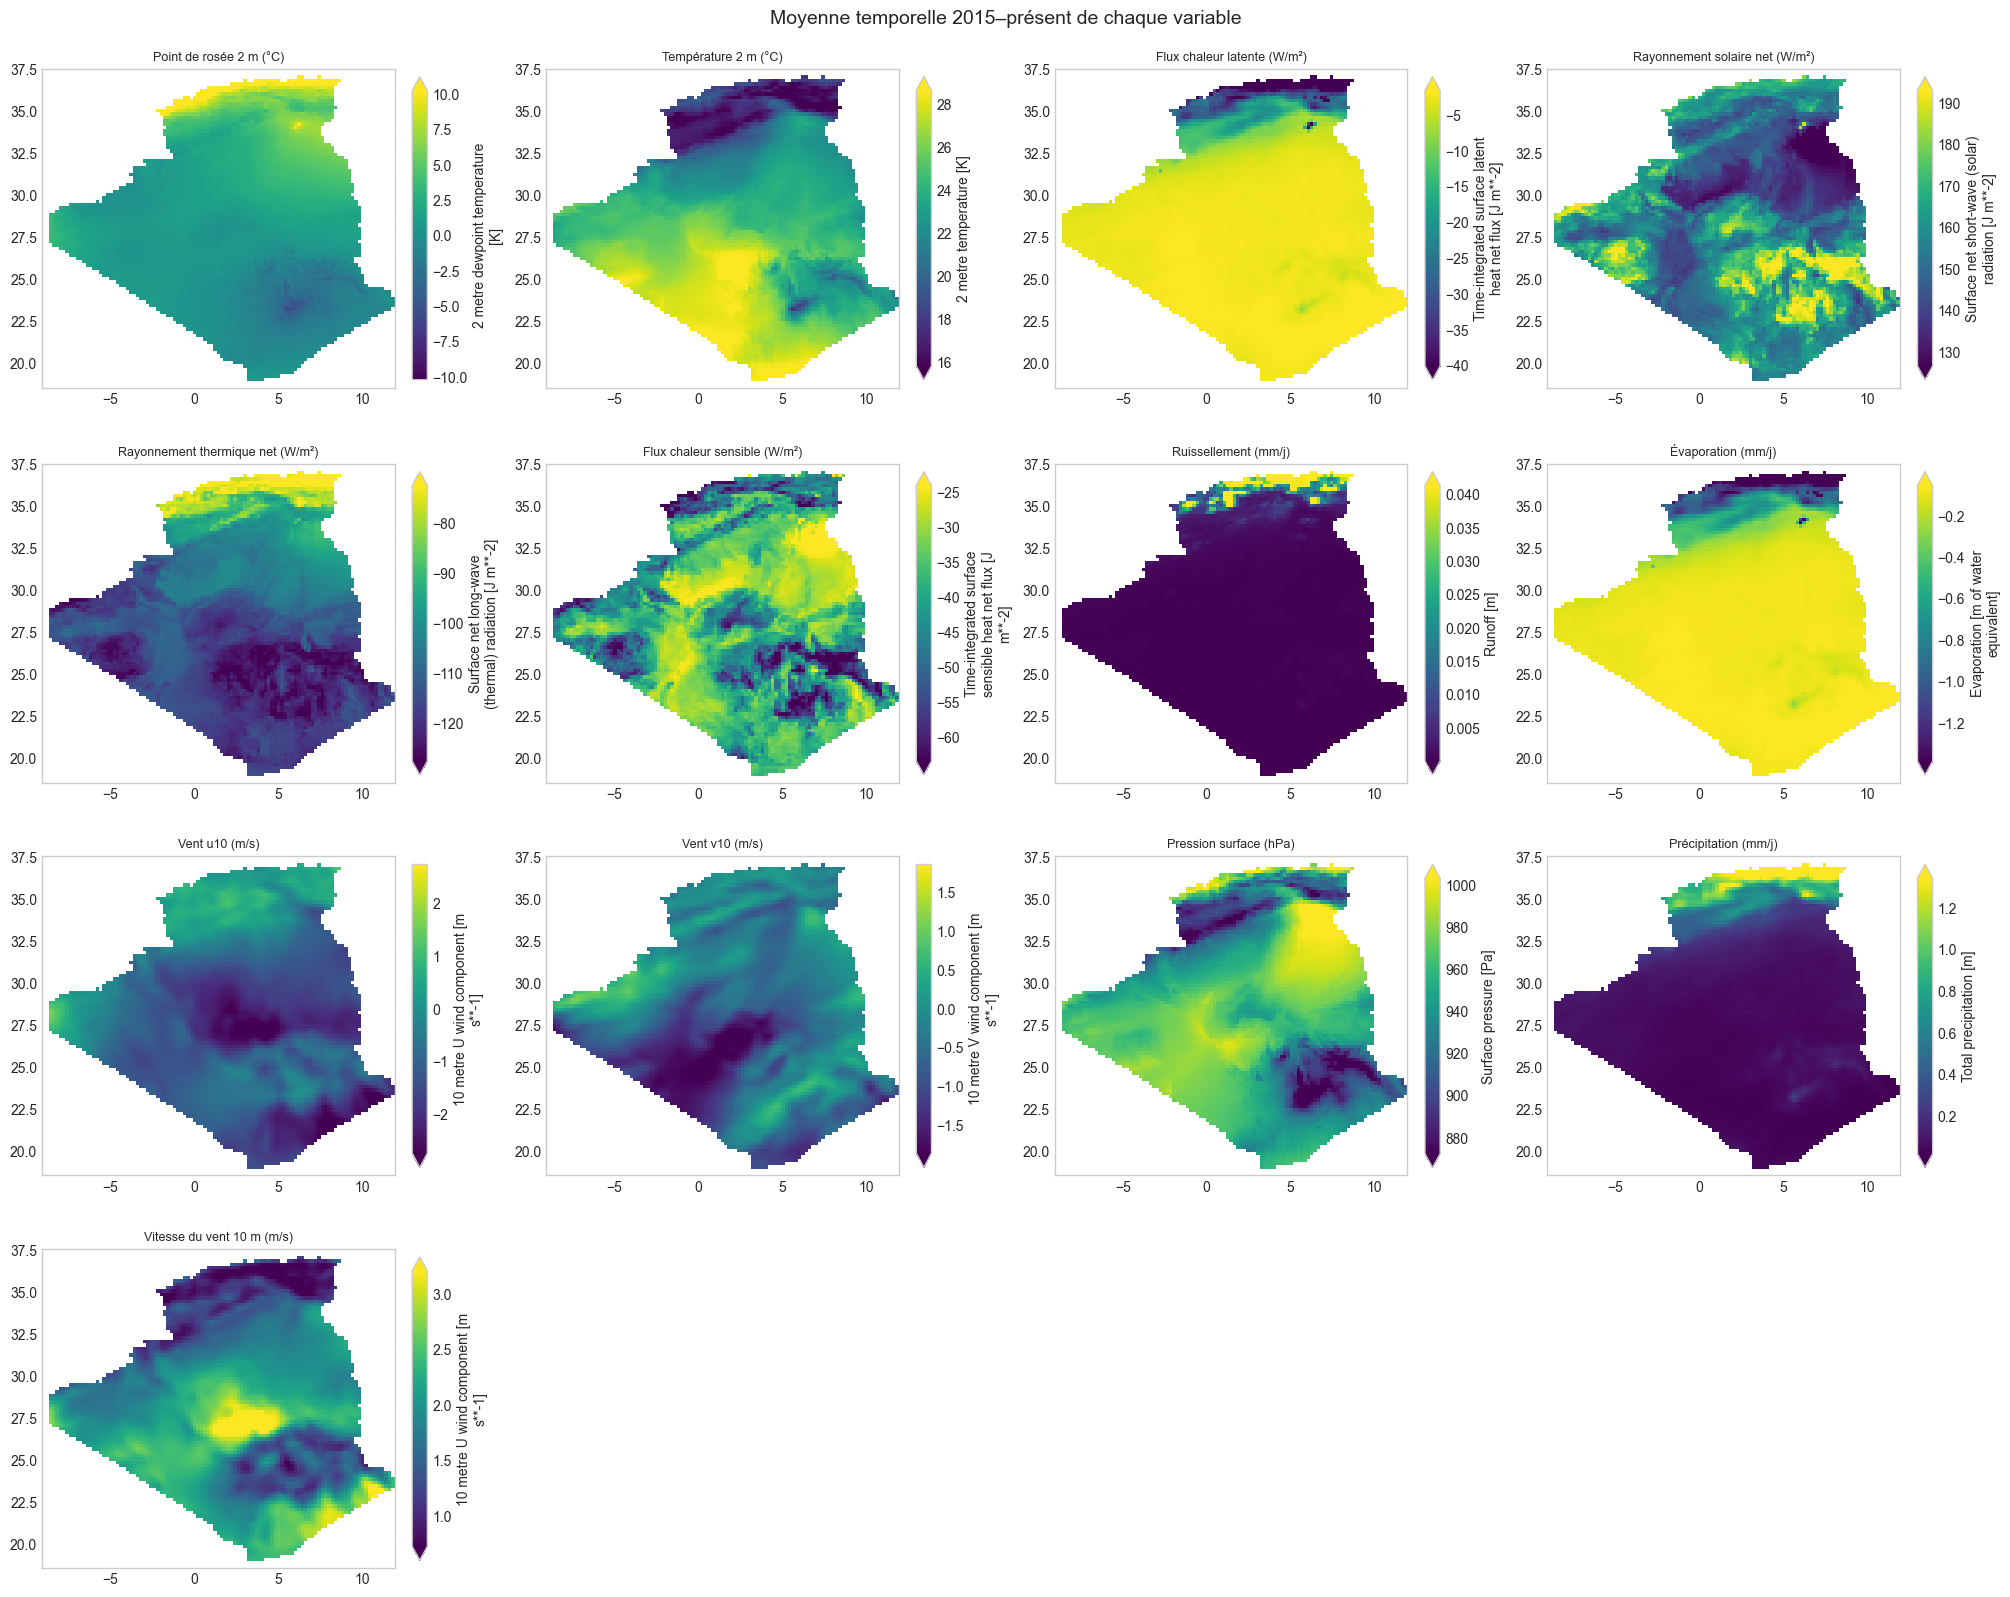

In [15]:
tmean = conv[BASE + ["wind10_speed"]].mean("valid_time")
fig, axes = plt.subplots(4, 4, figsize=(20, 16), constrained_layout=True)
for ax, v in zip(axes.flat, ALL):
    tmean[v].plot.pcolormesh(ax=ax, x="longitude", y="latitude", cmap="viridis", robust=True, cbar_kwargs={"shrink": .8})
    ax.set_title(LABELS[v], fontsize=9); ax.set_aspect("equal"); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.flat[len(ALL):]: ax.set_visible(False)
fig.suptitle("Moyenne temporelle 2015–présent de chaque variable", fontsize=14); plt.show()

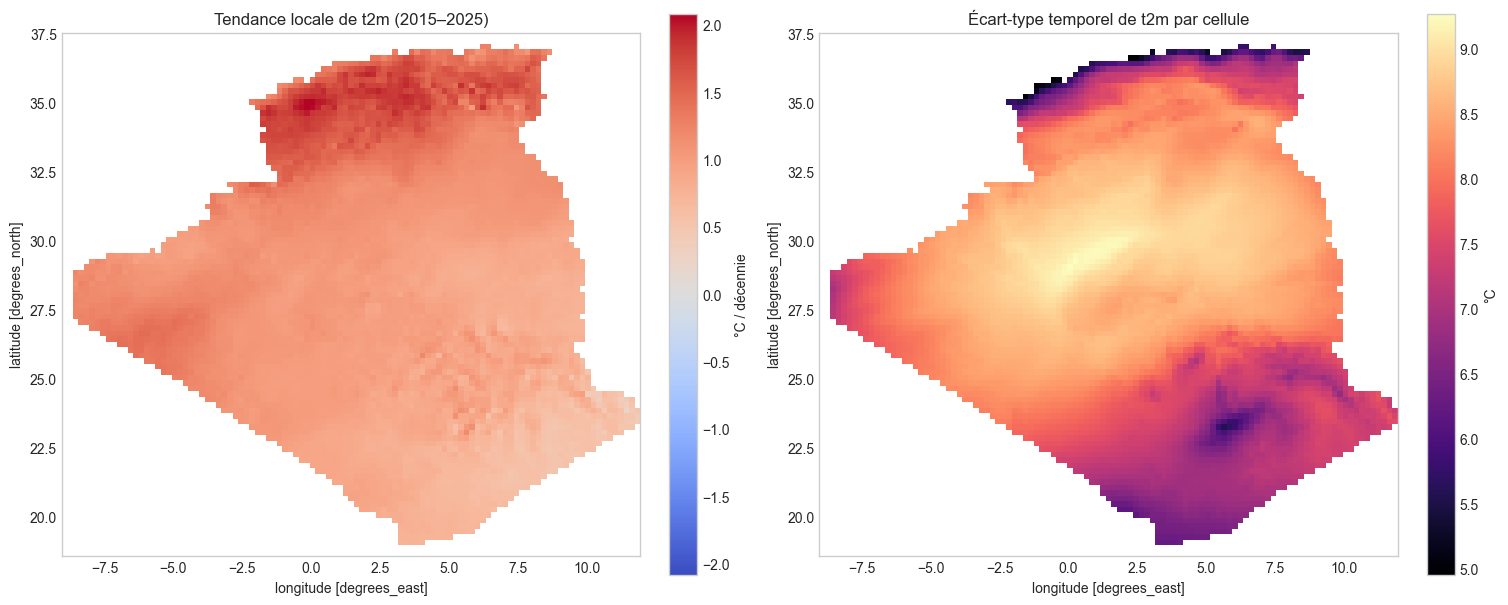

In [16]:
ann = conv["t2m"].sel(valid_time=slice("2015", "2025")).groupby("valid_time.year").mean()
slope = ann.polyfit("year", 1).polyfit_coefficients.sel(degree=1) * 10   # °C / décennie
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
slope.plot.pcolormesh(ax=axes[0], x="longitude", y="latitude", cmap="coolwarm", center=0, cbar_kwargs={"label": "°C / décennie"})
axes[0].set_title("Tendance locale de t2m (2015–2025)"); axes[0].set_aspect("equal")
conv["t2m"].std("valid_time").plot.pcolormesh(ax=axes[1], x="longitude", y="latitude", cmap="magma", cbar_kwargs={"label": "°C"})
axes[1].set_title("Écart-type temporel de t2m par cellule"); axes[1].set_aspect("equal"); plt.show()